In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('train.csv')

In [3]:
df.head()

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


In [4]:
df.dtypes

id                 int64
N_Days             int64
Drug              object
Age                int64
Sex               object
Ascites           object
Hepatomegaly      object
Spiders           object
Edema             object
Bilirubin        float64
Cholesterol      float64
Albumin          float64
Copper           float64
Alk_Phos         float64
SGOT             float64
Tryglicerides    float64
Platelets        float64
Prothrombin      float64
Stage            float64
Status            object
dtype: object

In [5]:
print(df["id"].is_unique)

True


In [6]:
df.isnull().sum()

id               0
N_Days           0
Drug             0
Age              0
Sex              0
Ascites          0
Hepatomegaly     0
Spiders          0
Edema            0
Bilirubin        0
Cholesterol      0
Albumin          0
Copper           0
Alk_Phos         0
SGOT             0
Tryglicerides    0
Platelets        0
Prothrombin      0
Stage            0
Status           0
dtype: int64

Пропусков не обнаружено

**id** - уникальный номер пациента

**N_Days** - сколько дней длилось наблюдение за пациентом

**Drug** - лекарство, которое принимал пациент: D-penicillamine или Placebo

**Age** - возраст в днях

**Sex** - пол (M, F)

*Внешние провления болезни*

**Ascites** - (Асцит) - скопление жидкости в брюшной полости (водянка живота). Тяжелый симптом

**Hepatomegaly** - Гепатомегалия. Увеличена ли печень в размерах

**Spiders** - Сосудистые "звездочки". Мелкике сосудистые сеточки на коже. Частый признак проблем с печенью.

**Edema** - Отеки. N - отеков нет. S - небольшие отеки (проходят от мочегонных). Y - сильные отеки (несмотря на лечение)

*Биохимия крови и анализы*

**Bilirubin** - Билирубин. Один из главных маркеров. Высокий билирубин дает желтуху и прямо указывает на разрушение печени

**Cholesterol** - Холестерин. Уровень общего холестерина

**Albumin** - Альбумин. Главный белок, который синтезирует печень. Если печень отказывает, альбумин падает.

**Copper** - Медь. Количество меди в моче. При больных желчных протоках медь плохо выводится и накапливается в организме.

**Alk_Phos** - Щелочная фосфатаза. Фермент, подсказывает, есть ли застой желчи

**SGOT** - печеночный фермент. Если клетки печени разрушаются, он выбрасывается в кровь (показатель резко растет)

**Tryglicerides** - Триглицериды (жиры в крови)

**Platelets** - Тромбоциты. Клетки крови, отввечающие за свертываемость. При циррозе их количество часто сильно падает.

**Prothrombin** - время свертывания крови. Если печень не работает, кровь сворачивается медленнее (показатель растет)

*Стадии болезни*

**Stage** - стадия цирроза: от 1 до 4, где 4 - это самая тяжелая стадия

**Status** - целевой признак. C - пациент жив. CL - пересадка печени. D - пациент умер.


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,7905.0,3952.000000,2282.121272,0.00,1976.00,3952.00,5928.00,7904.00
N_Days,7905.0,2030.173308,1094.233744,41.00,1230.00,1831.00,2689.00,4795.00
Age,7905.0,18373.146490,3679.958739,9598.00,15574.00,18713.00,20684.00,28650.00
Bilirubin,7905.0,2.594485,3.812960,0.30,0.70,1.10,3.00,28.00
Cholesterol,7905.0,350.561923,195.379344,120.00,248.00,298.00,390.00,1775.00
Albumin,7905.0,3.548323,0.346171,1.96,3.35,3.58,3.77,4.64
Copper,7905.0,83.902846,75.899266,4.00,39.00,63.00,102.00,588.00
Alk_Phos,7905.0,1816.745250,1903.750657,289.00,834.00,1181.00,1857.00,13862.40
SGOT,7905.0,114.604602,48.790945,26.35,75.95,108.50,137.95,457.25
Tryglicerides,7905.0,115.340164,52.530402,33.00,84.00,104.00,139.00,598.00


Выбросы в Bilirubin. У 75% людей равен 3.0 или меньше, а максимум получился 28.0. Критическое состояние.

Cholesterol показывает также высокое значение в 1775

Copper медиана 63, максимум - 588 (почти в 10 раз выше нормы)

Stage среднее 3.03 (в исследовании участвовали преимущественно люди на поздних, тяжелых стадиях болезни (3 и 4)


In [8]:
counts = df["Status"].value_counts()
percentages = df["Status"].value_counts(normalize=True) * 100
status_summary = pd.DataFrame(
    {"Количество пациентов": counts, "Процент (%)":
percentages.round(2)}
)

status_summary

,Количество пациентов,Процент (%)
Status,,
C,4965,62.81
D,2665,33.71
CL,275,3.48


Анализ целевой переменной показал дисбаланс классов.

C - почти 63% - большинство.

D - почти 34%, а CL всего 3.48%

In [9]:
df.describe(include=['object', 'category']).T

,count,unique,top,freq
Drug,7905,2,Placebo,4010
Sex,7905,2,F,7336
Ascites,7905,2,N,7525
Hepatomegaly,7905,2,Y,4042
Spiders,7905,2,N,5966
Edema,7905,3,N,7161
Status,7905,3,C,4965


Самый частый пол женщины, их 7336 из 7905 (почти 93% выборки)

Билиарный цирроз - это аутоимунное заболевание, которым в реальной жизни в 9 из 10 случаев болеют именно женщины среднего возраста.

Лекарство разделено практически поровну

Ascites - самый частый ответ N (нет асцита). Водянка живота встречается редко (только у тяжелых больных)

Edema - У большинства пациентов отеки не встречаются

In [10]:
all_numeric = [
    "N_Days",
    "Age",
    "Bilirubin",
    "Cholesterol",
    "Albumin",
    "Copper",
    "Alk_Phos",
    "SGOT",
    "Tryglicerides",
    "Platelets",
    "Prothrombin",
]

summary_all_num = df.groupby("Status")[all_numeric].median().T
summary_all_num.columns = [
    "C (Выжили)",
    "CL (Пересадка)",
    "D (Летальный исход)",
]

summary_all_num.round(1)

,C (Выжили),CL (Пересадка),D (Летальный исход)
N_Days,2216.0,1435.0,1216.0
Age,18137.0,15112.0,19256.0
Bilirubin,0.8,2.9,3.2
Cholesterol,288.0,336.0,331.0
Albumin,3.6,3.6,3.4
Copper,50.0,89.0,101.0
Alk_Phos,1082.0,1273.0,1580.0
SGOT,93.0,120.9,130.2
Tryglicerides,101.0,118.0,114.0
Platelets,271.0,271.0,228.0


Посмотрим по медиане

Выжившие наблюдались в среднем 2216 дней, умершие погибли в среднем через 1216 дней

В группе пересадки в среднем люди моложе

Alk_Phos и SGOT - Оба печеночных фермента заметно выше у группы летального исхода

Тромбоциты (Platelets) падают у группы D. (Кровь хуже свертывается, на что указывает и время свертывания Prothrombin)

In [11]:
symptoms = ["Ascites", "Hepatomegaly", "Spiders", "Edema", "Drug"]

for sym in symptoms:
    death_rate = (df[df["Status"] == "D"].groupby(df[sym]).size() / df.groupby(sym).size() * 100)
    print(f"\nЛетальность (%) в зависимости от признака '{sym}':")
    print(death_rate.round(1))


Летальность (%) в зависимости от признака 'Ascites':
Ascites
N    30.8
Y    91.8
dtype: float64

Летальность (%) в зависимости от признака 'Hepatomegaly':
Hepatomegaly
N    15.0
Y    51.6
dtype: float64

Летальность (%) в зависимости от признака 'Spiders':
Spiders
N    25.2
Y    60.0
dtype: float64

Летальность (%) в зависимости от признака 'Edema':
Edema
N    28.7
S    68.4
Y    97.1
dtype: float64

Летальность (%) в зависимости от признака 'Drug':
Drug
D-penicillamine    34.4
Placebo            33.1
dtype: float64


Процент смертности по симптомам

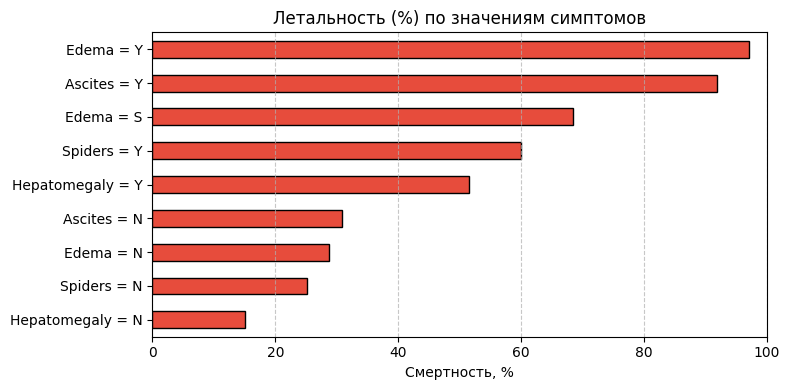

In [12]:
import matplotlib.pyplot as plt

symptoms = ["Ascites", "Hepatomegaly", "Spiders", "Edema"]

death_rates = {}
for sym in symptoms:
    rate = (
        df[df["Status"] == "D"].groupby(df[sym]).size() / df.groupby(sym).size() * 100
    )
    for val in rate.index:
        death_rates[f"{sym} = {val}"] = rate[val]

series_rates = pd.Series(death_rates).sort_values()

plt.figure(figsize=(8, 4))
series_rates.plot(kind="barh", color="#e74c3c", edgecolor="black")

plt.title("Летальность (%) по значениям симптомов")
plt.xlabel("Смертность, %")
plt.xlim(0, 100)
plt.grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

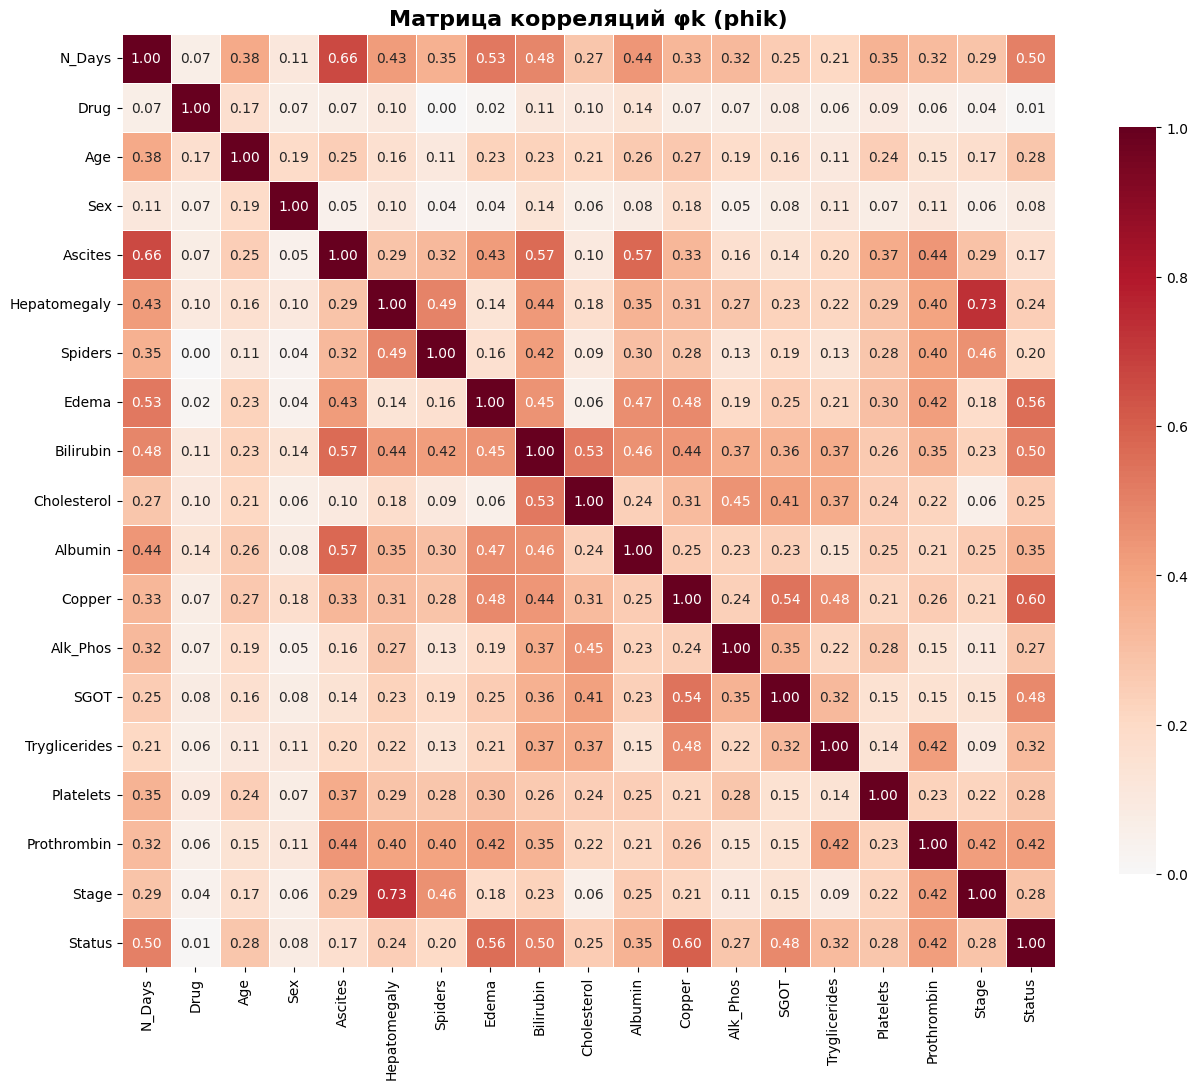

In [13]:
import matplotlib.pyplot as plt
import phik
import seaborn as sns
from phik.report import plot_correlation_matrix

interval_cols = [
    "N_Days",
    "Age",
    "Bilirubin",
    "Cholesterol",
    "Albumin",
    "Copper",
    "Alk_Phos",
    "SGOT",
    "Tryglicerides",
    "Platelets",
    "Prothrombin",
    "Stage",
]

phik_matrix = df.drop(columns=["id"], errors="ignore").phik_matrix(interval_cols=interval_cols)

fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(
    phik_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
    cbar_kws={"shrink": 0.8},
)

ax.set_title("Матрица корреляций φk (phik)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

Смотрю по целевой переменной Status

Copper - 0.6

Edema - 0.56 (среди симптомов выше всего)

Bilirubin и N_days по 0.5

SGOT - 0.48

Prothrombin - 0.42

Albumin - 0.35



Визуализация категориальных признаков (с долями статусов):


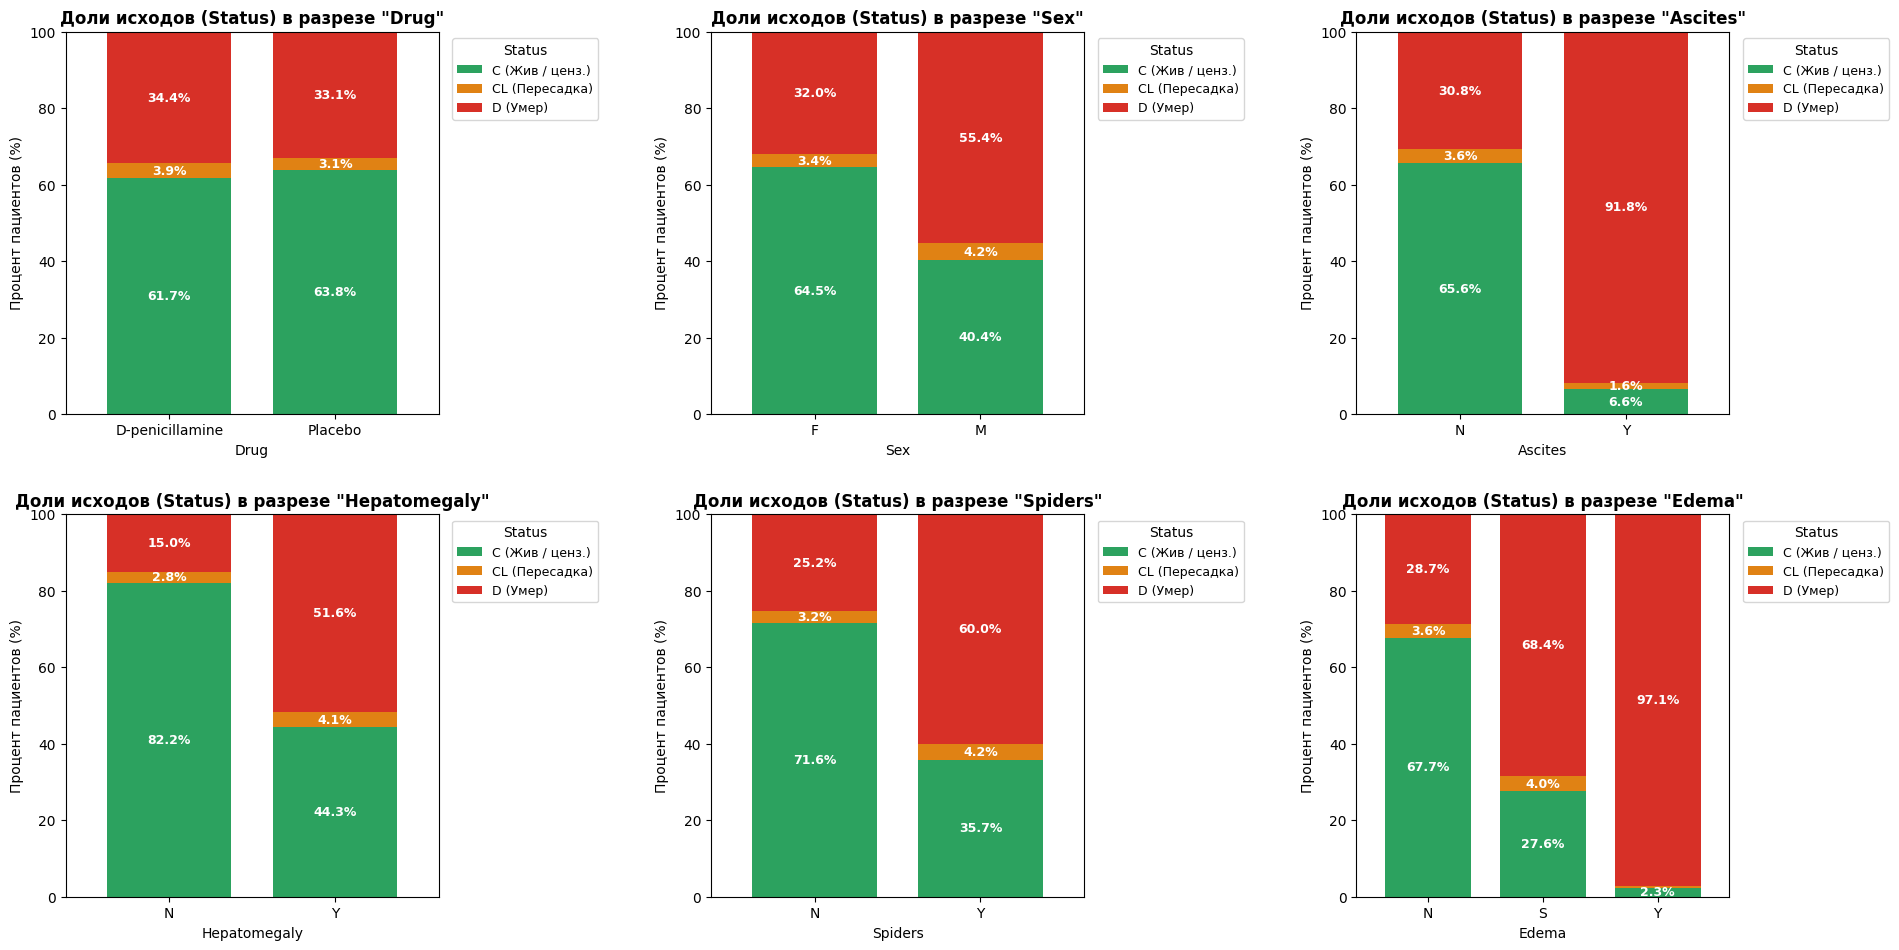

In [14]:
import math
import matplotlib.pyplot as plt


categorical_features = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']

# --- Визуализация Категориальных Признаков с Долями ---
print("\nВизуализация категориальных признаков (с долями статусов):")
n_cat = len(categorical_features)
n_cols_cat = 3
n_rows_cat = math.ceil(n_cat / n_cols_cat)


status_order = ['C', 'CL', 'D']
status_colors = ['#2ca25f', '#e08214', '#d73027']
status_labels = ['C (Жив / ценз.)', 'CL (Пересадка)', 'D (Умер)']

plt.figure(figsize=(n_cols_cat * 6.5, n_rows_cat * 5))

for i, col in enumerate(categorical_features):
    plt.subplot(n_rows_cat, n_cols_cat, i + 1)


    counts = df.groupby([col, 'Status'], observed=False).size().unstack(fill_value=0)

    counts = counts.reindex(columns=status_order, fill_value=0)


    totals = counts.sum(axis=1)


    percentages = counts.div(totals, axis=0) * 100


    ax = percentages.plot(
        kind='bar',
        stacked=True,
        ax=plt.gca(),
        color=status_colors,
        width=0.75
    )

    plt.title(f'Доли исходов (Status) в разрезе "{col}"', fontsize=12, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Процент пациентов (%)')
    plt.xticks(rotation=0)
    plt.ylim(0, 100)
    plt.legend(
        title='Status',
        labels=status_labels,
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        fontsize=9
    )


    for container in ax.containers:
        labels = [f'{v:.1f}%' if v > 1.5 else '' for v in container.datavalues]
        ax.bar_label(
            container,
            labels=labels,
            label_type='center',
            color='white',
            fontsize=9,
            fontweight='bold'
        )

plt.tight_layout(pad=2.5, w_pad=4.0)
plt.show()


Визуализация числовых признаков:


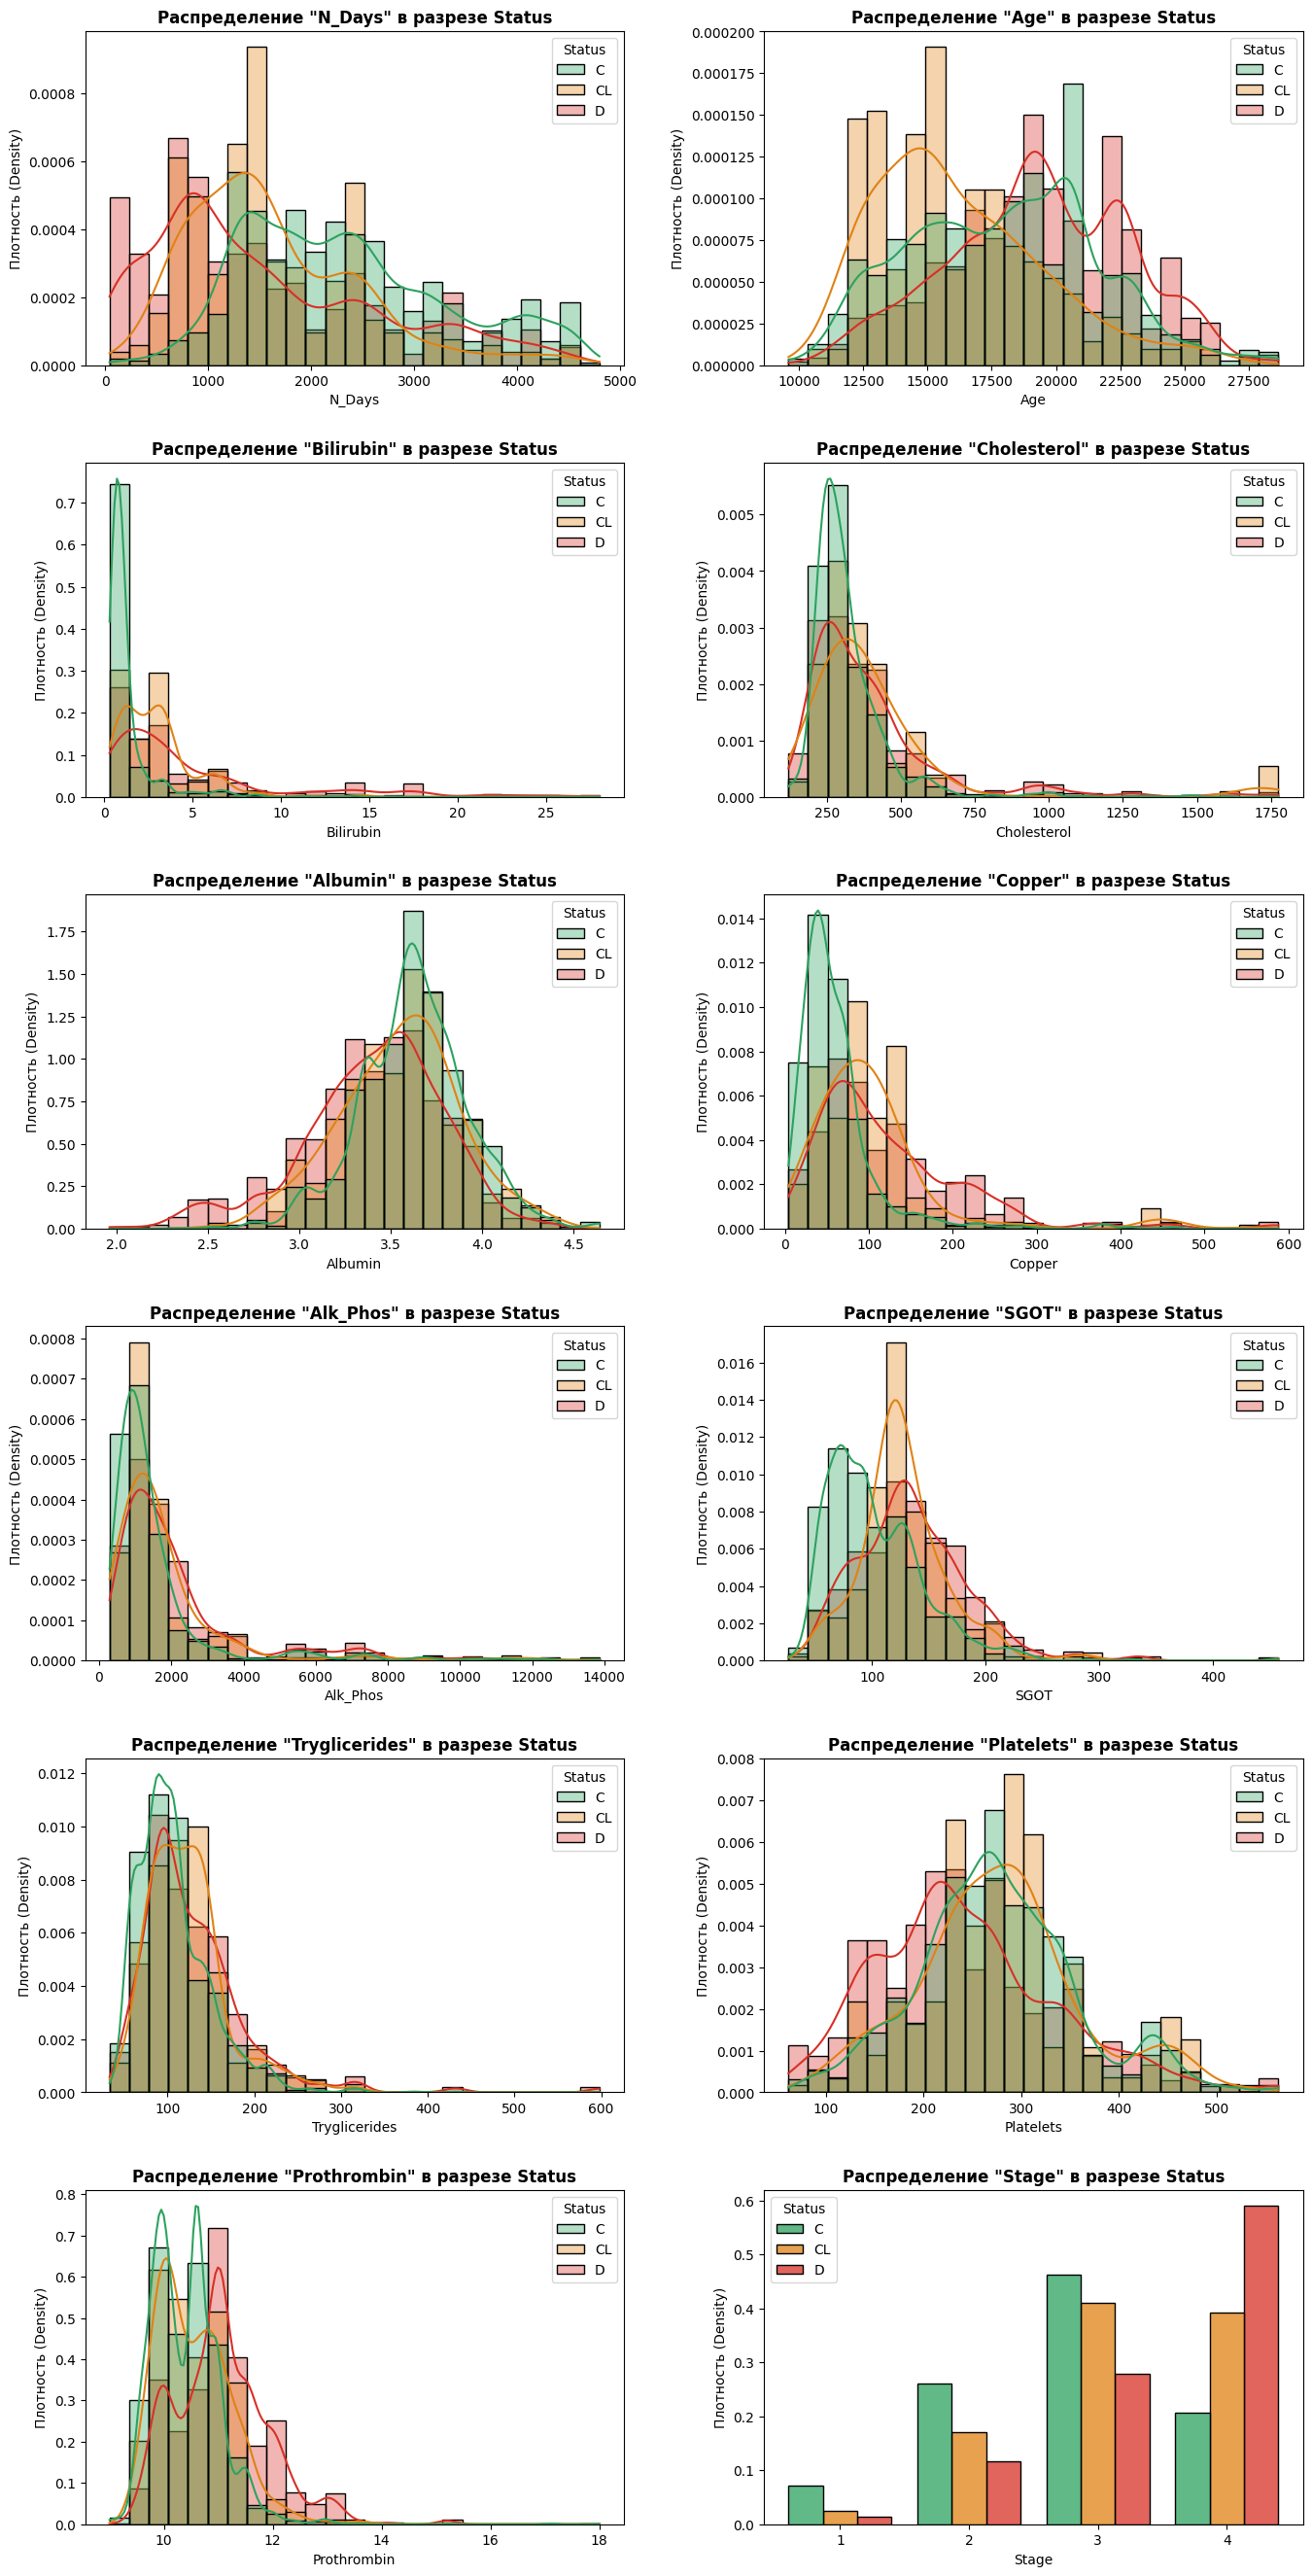

In [15]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = [
    'N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper',
    'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage'
]

print("\nВизуализация числовых признаков:")
n_num = len(numerical_features)
n_cols_num = 2
n_rows_num = math.ceil(n_num / n_cols_num)

status_order = ['C', 'CL', 'D']
status_palette = {'C': '#2ca25f', 'CL': '#e08214', 'D': '#d73027'}

plt.figure(figsize=(n_cols_num * 7, n_rows_num * 4.5))

for i, col in enumerate(numerical_features):
    ax = plt.subplot(n_rows_num, n_cols_num, i + 1)

    if col == 'Stage':
        sns.histplot(
            data=df, x=col, hue='Status', hue_order=status_order,
            palette=status_palette, stat='density', common_norm=False,
            discrete=True, multiple='dodge', shrink=0.8, ax=ax
        )
        ax.set_xticks([1, 2, 3, 4])
    else:
        sns.histplot(
            data=df, x=col, hue='Status', hue_order=status_order,
            palette=status_palette, kde=True, bins=25,
            stat='density', common_norm=False, alpha=0.35, ax=ax
        )

    ax.set_title(f'Распределение "{col}" в разрезе Status', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Плотность (Density)')

plt.tight_layout(pad=2.5)
plt.show()

Признак Drug убрать, все тяжелые симптомы в основном проявляются у людей в группе D

Билирубин слева сосредоточен, он растет для больных пациентов, а альбумин справа, он падает, можно будет через отношение в один совместить. SGOT явно изменяется, для C группы он слева, а для остальных увеличивается, Cooper так же.

В данных дисбаланс, очень мало класса CL, его как то по отдельным признакам сложно наверное определить, но может быть в сочетании: молодой возраст и тяжелые симптомы?? Он только в возрасте себя индивидуально и показывает, в остальном почти повторяет группу D.